# Data 620 Week 6 Assignment - 2-mode network: The attendance of 18 Southern Women at 14 social events
### Author: Pedro P Gatica Jr

## Introduction:
#### The Southern Women data, collected in the 1930s by the sociologists Allison Davis, Burleigh Gardner, and Mary Gardner for their study of social class in a small Southern U.S. town. The data records which of 18 women attended which of 14 social events (parties, luncheons, club meetings, and similar gatherings) over roughly nine months. Based on this attendance and on their fieldwork, the researchers concluded that the women divided into two overlapping cliques.
## Source:
#### Original source - Davis, A., Gardner, B. B., & Gardner, M. R. (1941). Deep South: A Social Anthropological Study of Caste and Class. University of Chicago Press

In [13]:
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite
import pandas as pd

In [14]:
G = nx.davis_southern_women_graph()
women = sorted(n for n, d in G.nodes(data=True) if d["bipartite"] == 0)
events = sorted((n for n, d in G.nodes(data=True) if d["bipartite"] == 1),
                key=lambda e: int(e[1:]))

## Step 1
#### Davis separates the women into two groups (names as they appear in the NetworkX data and then by number of events attended with the most active first.

In [15]:
group_A = {"Evelyn Jefferson", "Laura Mandeville", "Theresa Anderson",
           "Brenda Rogers", "Charlotte McDowd", "Frances Anderson",
           "Eleanor Nye", "Pearl Oglethorpe", "Ruth DeSand"}
grp = {w: ("A" if w in group_A else "B") for w in women}
colors = {"A": "#2a6fbb", "B": "#d9622b"}

women_ordered = sorted(women, key=lambda w: (grp[w], -G.degree(w)))

## Step 2

#### Create a two-column layout graph: women on the left, events on the right

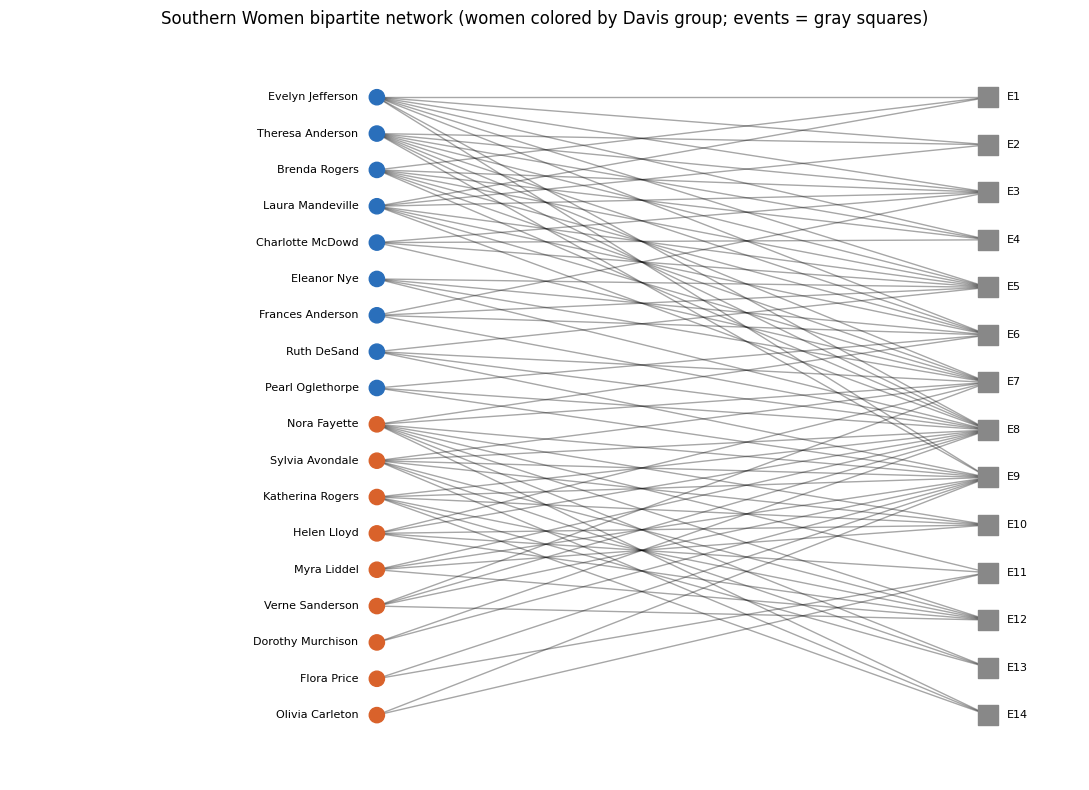

In [16]:
pos = {}
for i, w in enumerate(women_ordered):
    pos[w] = (0, -i)
for j, e in enumerate(events):
    pos[e] = (1, -(j * (len(women) - 1) / (len(events) - 1)))

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G, pos, alpha=0.35, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=women,
                       node_color=[colors[grp[w]] for w in women],
                       node_size=120, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=events, node_color="#888888",
                       node_shape="s", node_size=200, ax=ax)

# Labels placed beside the nodes
for w in women:
    ax.text(-0.03, pos[w][1], w, ha="right", va="center", fontsize=8)
for e in events:
    ax.text(1.03, pos[e][1], e, ha="left", va="center", fontsize=8)

ax.set_xlim(-0.6, 1.15)
ax.axis("off")
ax.set_title("Southern Women bipartite network "
             "(women colored by Davis group; events = gray squares)")
plt.tight_layout()
plt.show()

### The two colors

##### The blue women (top 9) and orange women (bottom 9) are the two cliques that the original researchers identified. Notice that the blue women’s lines mostly go to the upper and middle events (E1 through E9), while the orange women’s lines mostly go to the middle and lower events (E7 through E14). In other words, the town’s social life seems to have split into two circles, each with its own favorite gatherings.

### What stands out

##### The lines run diagonally because each group heads toward “its” events. Blue women cluster toward the top right, orange toward the bottom right.
##### Some women are very active. Evelyn Jefferson, Theresa Anderson, Nora Fayette, and Sylvia Avondale have many lines fanning out. Others, like Dorothy Murchison, Flora Price, and Olivia Carleton, have only a few lines, so they attended fewer events.
##### Some events are crowded. E8 and E9 receive a big bundle of lines from both colors. These were popular gatherings that drew from both circles.
##### Some events are small. E1, E2, E11, E13, and E14 have only a few lines going in, so they were smaller or more exclusive affairs.
##### The groups overlap. The two circles aren’t completely separate. Women from both colors show up at events like E7, E8, and E9, which means those events were where the two groups mixed. A few women, especially in the middle of the list (Pearl Oglethorpe, Nora Fayette), sit near the boundary and connect to events on both sides.

## Step 3
#### Create a women x women projection graph with edge weight = number of events attended together with a spring layout showing women who share more events are pulled closer together.

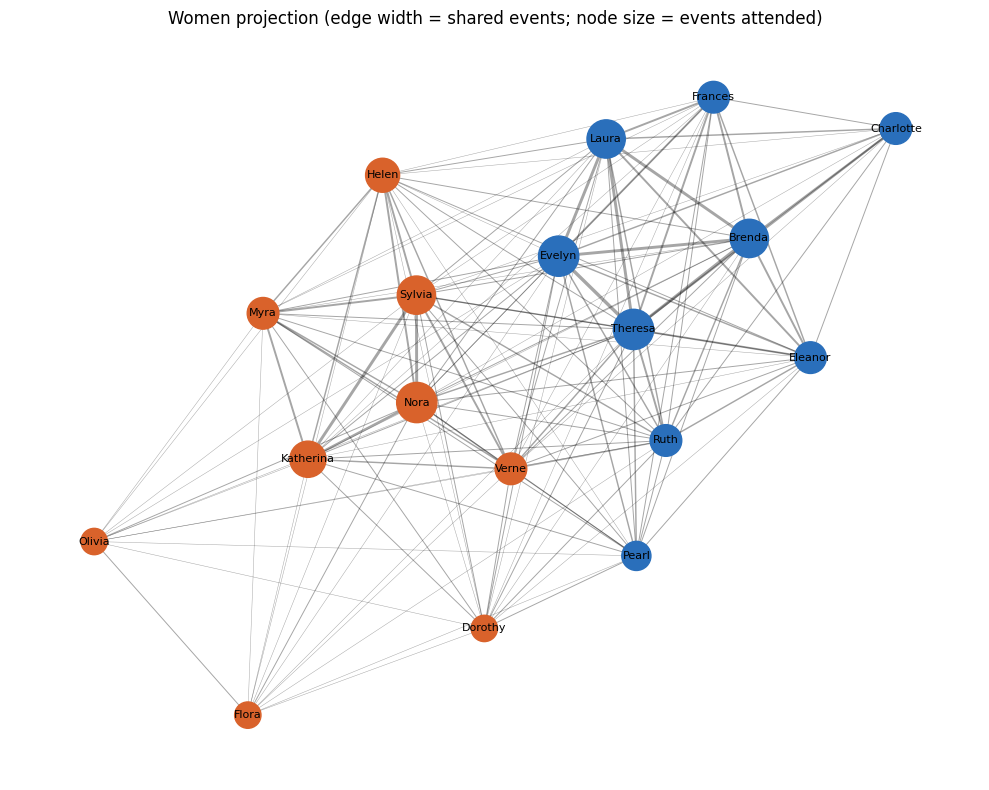

In [19]:
# Women x women projection: edge weight = number of events attended together
W = bipartite.weighted_projected_graph(G, women)

# Spring layout: women who share more events are pulled closer together
pos = nx.spring_layout(W, weight="weight", seed=4, k=0.9)

edge_weights = [W[u][v]["weight"] for u, v in W.edges()]

fig, ax = plt.subplots(figsize=(10, 8))
nx.draw_networkx_edges(W, pos, width=[w * 0.35 for w in edge_weights],
                       alpha=0.35, ax=ax)
nx.draw_networkx_nodes(W, pos,
                       node_color=[colors[grp[w]] for w in W],
                       node_size=[200 + 80 * G.degree(w) for w in W],
                       ax=ax)
nx.draw_networkx_labels(W, pos,
                        {w: w.split()[0] for w in W},  # first names only
                        font_size=8, ax=ax)

ax.set_title("Women projection (edge width = shared events; "
             "node size = events attended)")
ax.axis("off")
plt.tight_layout()
plt.show()

### Women-to-women graph

##### This graph drops the events and connects two women if they went to the same events. A thicker line means they shared more events, and a bigger dot means she attended more. Women who shared lots of events get pulled close together.

##### The result is two clumps, one blue and one orange. Women within a group shared about 3 events on average, while women from different groups shared only about 1.6. The groups are real, but they aren’t walled off.

##### The centrality table measures who sits on the paths linking everyone else, which is roughly who acts as a social bridge. The top five:

##### Nora Fayette (orange): 8 events, the strongest bridge.
##### Evelyn Jefferson (blue): 8 events.
##### Theresa Anderson (blue): 8 events, and she shared events with the most people overall.
##### Sylvia Avondale (orange): 7 events.
##### Laura Mandeville (blue): 7 events.

## The tight friend circles

##### The last cell looks for groups of three or more women who each shared at least 3 events with every other member. It finds:

##### An orange circle of 6: Nora, Sylvia, Helen, Katherina, Myra, and Verne.
##### Blue circles of 5 to 6: Evelyn, Theresa, Laura, Brenda, Eleanor, and either Ruth or Frances, overlapping heavily.
##### Bridge circles: Theresa teams up with Sylvia, Verne, and either Nora or Ruth, so Theresa links the two sides.

## Step 4

#### create an events x events projection where edge weight = number of women who attended both with a spring layout where events that share more attendees are pulled closer together.

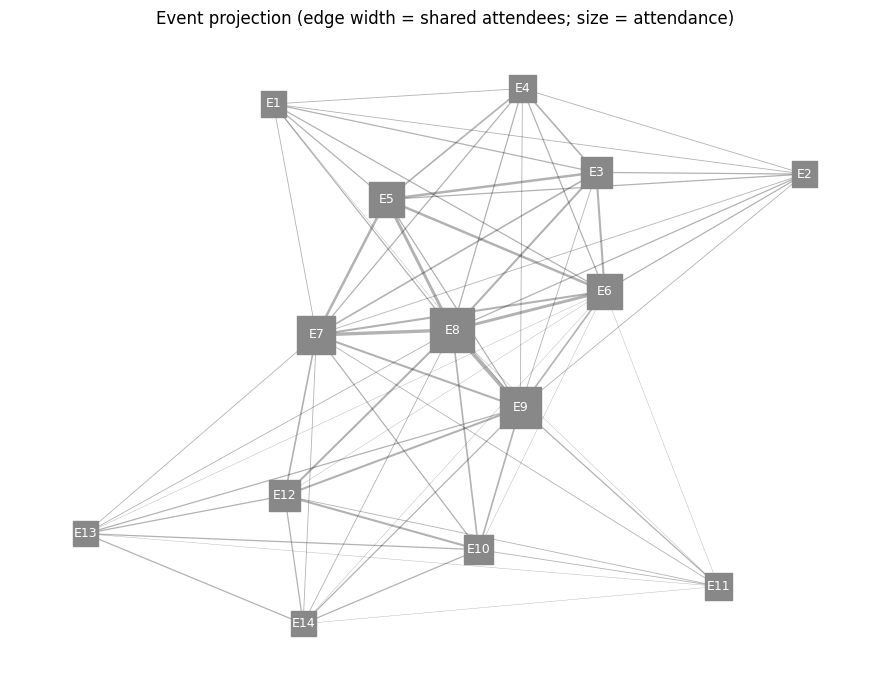

In [20]:
# Events x events projection: edge weight = number of women who attended both
E = bipartite.weighted_projected_graph(G, events)

# Spring layout: events that share more attendees are pulled closer together
pos = nx.spring_layout(E, weight="weight", seed=2, k=0.8)

edge_weights = [E[u][v]["weight"] for u, v in E.edges()]

fig, ax = plt.subplots(figsize=(9, 7))
nx.draw_networkx_edges(E, pos, width=[w * 0.3 for w in edge_weights],
                       alpha=0.3, ax=ax)
nx.draw_networkx_nodes(E, pos, node_color="#888888", node_shape="s",
                       node_size=[150 + 60 * G.degree(e) for e in E],
                       ax=ax)
nx.draw_networkx_labels(E, pos, font_size=9, font_color="white", ax=ax)

ax.set_title("Event projection (edge width = shared attendees; "
             "size = attendance)")
ax.axis("off")
plt.tight_layout()
plt.show()

### Event-to-event graph

##### This is the same idea flipped: two events are linked if many of the same women attended both. The numbers show a clean split:

#### E1 to E5: only blue women attended.
#### E6 to E9: a mix of both groups.
#### E10 to E14: only orange women attended.

#### So the events form a line from “blue-only” through “mixed” to “orange-only.” E8 and E9 are the meeting ground, with 14 and 12 attendee

#### E8 and E9 are by far the most important connectors. Lots of social “traffic” passes through them, and without them the two circles would barely touch.

## Step 5

#### Calculate weighted centrality measures by women.

In [21]:
# Centrality measures
betw_proj = nx.betweenness_centrality(W)          # projection, unweighted
close_proj = nx.closeness_centrality(W)           # projection
w_degree = dict(W.degree(weight="weight"))        # sum of shared events
betw_bip = nx.betweenness_centrality(G)           # full bipartite graph

cent = pd.DataFrame({
    "woman": women,
    "events": [G.degree(w) for w in women],
    "weighted_degree": [w_degree[w] for w in women],
    "betweenness_proj": [round(betw_proj[w], 3) for w in women],
    "closeness_proj": [round(close_proj[w], 3) for w in women],
    "betweenness_bipartite": [round(betw_bip[w], 3) for w in women],
}).sort_values("betweenness_bipartite", ascending=False)

print(cent.to_string(index=False))
cent.to_csv("women_centrality.csv", index=False)

            woman  events  weighted_degree  betweenness_proj  closeness_proj  betweenness_bipartite
     Nora Fayette       8               43             0.010           1.000                  0.109
 Evelyn Jefferson       8               50             0.010           1.000                  0.092
 Theresa Anderson       8               57             0.010           1.000                  0.084
  Sylvia Avondale       7               46             0.010           1.000                  0.069
 Laura Mandeville       7               45             0.003           0.895                  0.049
    Brenda Rogers       7               46             0.003           0.895                  0.047
 Katherina Rogers       6               37             0.005           0.944                  0.045
      Helen Lloyd       5               34             0.010           1.000                  0.041
      Ruth DeSand       4               40             0.010           1.000                  0.016


### What this table is telling you

##### Each row is one woman, and each column is a different way of asking “how important is she in this social web?” The answers differ depending on what you mean by “important.”

#### weighted_degree: 
##### If you add up the number of events she shared with each of the other 17 women, this is the total. It measures how much overlap she had with everyone else. It isn’t the same as attendance. Ruth DeSand went to only 4 events but scores 40, because she picked popular ones where lots of people were present. Charlotte McDowd also went to 4 events but scores only 24, because she went to smaller gatherings. Dorothy Murchison went to just 2 events but scores 24, which means her two events were crowded ones, while Flora Price and Olivia Carleton (also 2 events, score 14) chose small ones.

#### closeness_proj: 
##### How directly she’s connected to everyone else. A score of 1.000 means she shared at least one event with every one of the other 17 women. Seven women hit that mark: Nora, Evelyn, Theresa, Sylvia, Helen, Ruth, and Verne. The lowest score is Charlotte McDowd (0.739), who never shared an event with about 6 of the other women, followed by Flora and Olivia (0.773). Those three are the most socially “out of the loop.”

#### betweenness_proj:
##### How often she sits on the shortest path between two other women, like a go-between. In this version the numbers are almost all tiny and tied (mostly 0.010, 0.005, 0.003, 0). That’s because nearly everyone shares an event with nearly everyone, so no one needs a middleman. You can mostly ignore this column.

#### betweenness_bipartite: 
##### The same go-between idea, but measured on the original graph with both women and events. This is the most revealing column, because it captures who connects different parts of the network through the events they attend.

### Who comes out on top

##### The betweenness_bipartite ranking is a good summary of who mattered most:

##### Nora Fayette (0.109) is the strongest connector, even though Theresa has more total overlap.
##### Evelyn Jefferson (0.092)
##### Theresa Anderson (0.084), who also has the highest weighted_degree (57), so she shared the most events with the most people.
##### Sylvia Avondale (0.069)

##### These four attended 7 or 8 events each, which fits the pattern: the more events you attend, the more connections you carry. Notice that Nora and Sylvia are in the orange group and Evelyn and Theresa are in the blue, so each group has its own central figures.

##### At the bottom are Dorothy Murchison, Flora Price, Olivia Carleton, and Pearl Oglethorpe, who attended only 2 or 3 events each. They’re on the edge of the network.

## Step 6

#### Calculate weighted centrality measures by event.

In [25]:
# Events x events projection
E = bipartite.weighted_projected_graph(G, events)

# Centrality measures
betw_bip = nx.betweenness_centrality(G)        # full bipartite graph
close_proj = nx.closeness_centrality(E)        # projection
w_degree = dict(E.degree(weight="weight"))     # sum of shared attendees

cent = pd.DataFrame({
    "event": events,
    "attendees": [G.degree(e) for e in events],
    "weighted_degree": [w_degree[e] for e in events],
    "betweenness_bipartite": [round(betw_bip[e], 3) for e in events],
    "closeness_proj": [round(close_proj[e], 3) for e in events],
}).sort_values("betweenness_bipartite", ascending=False)

print(cent.to_string(index=False))
cent.to_csv("event_centrality.csv", index=False)

event  attendees  weighted_degree  betweenness_bipartite  closeness_proj
   E8         14               59                  0.237           1.000
   E9         12               46                  0.219           1.000
   E7         10               48                  0.126           1.000
   E6          8               41                  0.063           1.000
   E5          8               38                  0.037           0.722
  E11          4               13                  0.019           0.722
  E12          6               28                  0.018           0.722
   E3          6               32                  0.018           0.722
  E10          5               25                  0.011           0.722
   E4          4               23                  0.007           0.722
   E1          3               19                  0.002           0.722
   E2          3               20                  0.002           0.722
  E13          3               18                  

### What this table is telling you

#### attendees: 
##### How many of the 18 women showed up. This is simply how big or popular the event was.

#### weighted_degree: 
##### If you add up, for every other event, how many of the same women attended both, this is the total. It measures how much an event’s guest list overlaps with all the others. A high score means its attendees were out and about at lots of other events too. A low score means its guests mostly went there and nowhere else.

#### closeness_proj: 
##### How directly an event connects to all the others through shared guests. A score of 1.000 means it shares at least one attendee with every other event. Only E6, E7, E8, and E9 reach that mark. Every other event scores 0.722, which means each has to go through a stepping-stone event to reach some of the others.

#### betweenness_bipartite: 
##### How often the event sits on the shortest path linking two other parts of the network. Think of it as a crossroads. This is the most revealing column.

##### E8 and E9 have by far the highest betweenness (0.237 and 0.219), more than the rest combined in some comparisons. E8 is also the biggest event (14 attendees) and has the highest weighted degree (59). From the earlier group breakdown, E8 drew 8 blue and 6 orange women, and E9 drew 4 blue and 8 orange. They are the places where the two circles actually mixed. If you removed them, the two groups would have very little connecting them.

##### E7 is the next bridge. It has 10 attendees (6 blue, 4 orange) and a solid betweenness of 0.126. It’s another meeting ground, though a smaller one.

##### E6 and E5 are blue-leaning. E6 has a perfect closeness score and decent overlap, but it was almost entirely blue women (7 blue, 1 orange). E5 was blue-only. They’re popular within their own circle but don’t do much bridging.

## Step 7

##### Count attendees from each group at each event

In [22]:
# Count attendees from each group at each event
rows = []
for e in events:
    attendees = list(G.neighbors(e))   # the women connected to this event
    rows.append({
        "event": e,
        "A": sum(grp[w] == "A" for w in attendees),
        "B": sum(grp[w] == "B" for w in attendees),
    })

eg = pd.DataFrame(rows)
print(eg.to_string(index=False))
eg.to_csv("event_by_group.csv", index=False)

event  A  B
   E1  3  0
   E2  3  0
   E3  6  0
   E4  4  0
   E5  8  0
   E6  7  1
   E7  6  4
   E8  8  6
   E9  4  8
  E10  0  5
  E11  0  4
  E12  0  6
  E13  0  3
  E14  0  3


## There are three zones

##### Blue-only events (E1 to E5): Only group A women attended. E5 was the biggest, with 8 of the 9 blue women, and E3 drew 6. Not a single orange woman went to any of these.

##### Mixed events (E6 to E9): Here the groups overlap.

##### E6: 7 blue, 1 orange. This is almost entirely blue, and the single orange guest is the only crossover.
##### E7: 6 blue, 4 orange. This is a fairly even mix.
##### E8: 8 blue, 6 orange. This is the biggest event, with a nearly even split.
##### E9: 4 blue, 8 orange. This one tilts orange.

##### Orange-only events (E10 to E14): Only group B women attended. E10 and E12 were the largest (5 and 6), and E13 and E14 were small (3 each).

## What stands out
##### The two groups almost never share a room outside E7 to E9. Only 4 of the 14 events had both blue and orange women present, and E6’s lone orange guest barely counts. For the other 10 events, everyone there belonged to the same group.
##### The events run in a line, from blue-only on one end, through a mixed middle, to orange-only on the other end. Moving from E1 to E14, the blue crowd fades out as the orange crowd takes over, and E8 is roughly where they trade places.
##### E8 and E9 are the real meeting ground. They’re the two events where each group has a substantial presence, which is exactly why the earlier centrality table rated them the most important connectors in the whole network.
##### Blue women went to more of the crowded events. Counting up the attendance, group A made 49 event visits and group B made 39, so the blue group was somewhat more socially active overall.

## In Conclusion

##### This work examined which of 18 women attended which of 14 social events in a small Southern town in the 1930s, and asked whether that attendance pattern reveals hidden social structure.

##### The main finding is that the town split into two social circles. Ten of the 14 events were attended by only one group, and just four events (E6 to E9) brought both groups together. The women who shared the most events with each other were almost always in the same group, which supports the two-clique interpretation first proposed by Davis, Gardner, and Gardner.

##### The circles were connected by a few key people and places. Nora Fayette, Evelyn Jefferson, Theresa Anderson, and Sylvia Avondale were the most central women, and E8 and E9 were the most important events, acting as the main meeting ground between the groups. Women who attended only two or three small events sat on the fringe.

##### The broader lesson is that attendance records alone can expose social structure. Without asking anyone who their friends were, the network revealed who belonged to which circle, who linked the circles, and which gatherings mattered most.

### YouTube Video Presentation: 

https://youtu.be/ZM2W9HYgX9g

Please set video quality to 720p